# Лабораторная работа №2. Классификация пассажиров Titanic

Цель: предсказать `Survived` (1 — выжил), пройти EDA, подготовку данных,
baseline, сравнение пяти моделей, интерпретацию и анализ ошибок.
Источник: https://www.kaggle.com/datasets/yasserh/titanic-dataset .
Требования взяты из `lab02.pdf`, подходы — из `preza.pdf`,
`classification.ipynb`, `metrics.ipynb`. Исходные материалы задания сохранены отдельно.

Главная метрика — F1 положительного класса, необходим строго F1 > 0.70.
Отдельный общий тест группы не предоставлен. Фиксируем 80/20,
random_state=42, stratify=y (как в презентации); результаты относятся к этому
локальному разбиению. Для официального leaderboard нужен тест преподавателя.
Модель выбираем по 5-fold CV на train до просмотра test, пороги не подбираем.

## Как запустить этот файл

Этот ноутбук содержит всё решение: исходные данные Titanic, код, результаты обучения,
таблицы, графики и выводы. Дополнительные файлы и скачивание датасета не нужны.
Откройте файл в Jupyter или VS Code и выполните **Run All / Выполнить все ячейки**.
Данные встроены без изменений (сжатие zlib + base64), контрольная сумма проверяется при чтении.
Результаты сохраняются внутри ноутбука; отдельных папок и отчётов код не создаёт.

Проверено на Python 3.14. Если библиотек нет, выполните в отдельной ячейке:

```python
%pip install numpy==2.5.4 pandas==3.1.0 scipy==1.18.1 scikit-learn==1.9.1 matplotlib==3.11.2 ipython==9.17.1 tabulate==0.10.0
```

После установки при необходимости перезапустите ядро. Подбор параметров выполняется
на обучающей выборке; финальные оценки относятся к локальному тесту 80/20,
поскольку общий тест преподавателя не предоставлен.


In [1]:
from io import StringIO
import base64
import zlib
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
artifacts = {}  # Дополнительные таблицы в памяти, без внешних файлов
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
report = []
def note(text):
    display(Markdown(text))
    report.append(text)
def table(frame):
    display(frame)
    report.append(frame.to_markdown(index=True, floatfmt='.4f'))
def figure(name):
    plt.tight_layout()
    plt.show()

versions = {'python': platform.python_version(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
            'matplotlib': matplotlib.__version__}
print(versions)
# Точная копия Titanic-Dataset.csv из Kaggle, встроенная в ноутбук.
TITANIC_BASE64 = '...'
csv_bytes = zlib.decompress(base64.b64decode(TITANIC_BASE64))
assert hashlib.sha256(csv_bytes).hexdigest() == '7d118fef8b6ccf7f81111877bc388536f7b1e498a655e3d649d19aaa010e9f6f'
df = pd.read_csv(StringIO(csv_bytes.decode('utf-8')))
assert df.shape == (891, 12) and set(df.Survived.unique()) == {0, 1}
print('SHA256:', hashlib.sha256(csv_bytes).hexdigest())
display(df.head())

{'python': '3.14.4', 'numpy': '2.5.4', 'pandas': '3.1.0', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2'}
SHA256: 7d118fef8b6ccf7f81111877bc388536f7b1e498a655e3d649d19aaa010e9f6f


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. Первичный анализ
PassengerId — идентификатор; Name, Ticket и Cabin могут идентифицировать
пассажира или группу совместно путешествующих. Прямой утечки целевого признака
в исходных 12 столбцах не обнаружено. Идентификация и утечка — разные проблемы:
эти поля исключаются из модели для ограничения запоминания. Общий билет у
нескольких пассажиров означает возможную зависимость наблюдений при случайном
разбиении. Такой эксперимент оценивает именно случайный passenger split,
а не обобщение на совершенно новые семьи или группы билетов.

,dtype,missing,missing_pct,unique
PassengerId,int64,0,0.000000,891
Survived,int64,0,0.000000,2
Pclass,int64,0,0.000000,3
Name,str,0,0.000000,891
Sex,str,0,0.000000,2
Age,float64,177,19.865320,88
SibSp,int64,0,0.000000,7
Parch,int64,0,0.000000,7
Ticket,str,0,0.000000,681
Fare,float64,0,0.000000,248


Полных дубликатов: 0
Дубликатов PassengerId: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


,count,share
Survived,,
0,549,0.616162
1,342,0.383838


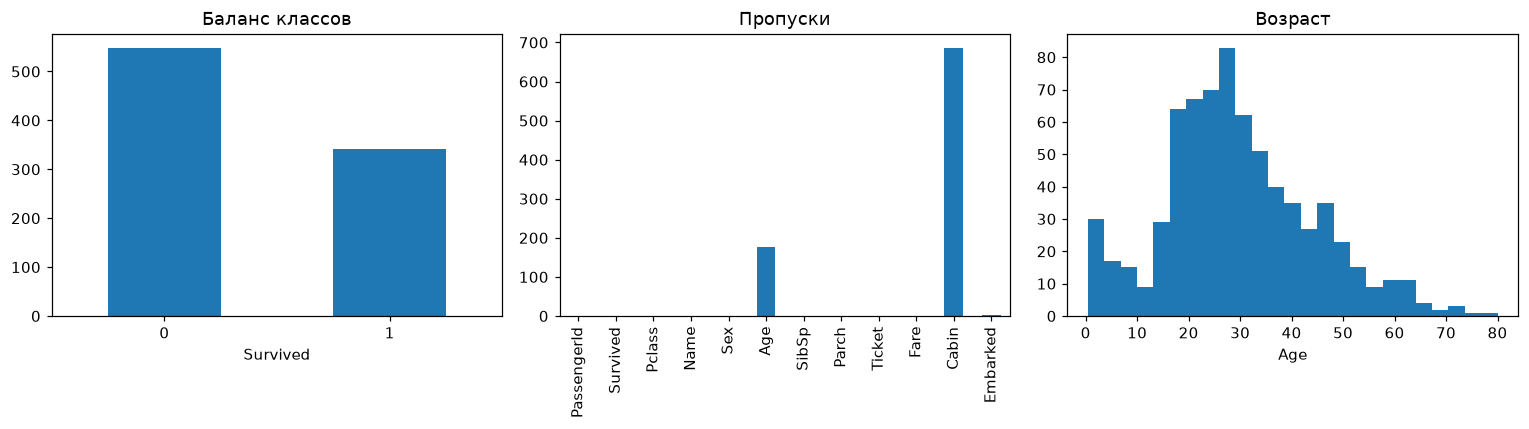

In [2]:
summary = pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(),
                        'missing_pct': df.isna().mean()*100,
                        'unique': df.nunique()})
table(summary)
print('Полных дубликатов:', df.duplicated().sum())
print('Дубликатов PassengerId:', df.PassengerId.duplicated().sum())
display(df.describe(include='all').T)
table(df.Survived.value_counts().sort_index().to_frame('count').assign(share=lambda x: x['count']/len(df)))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
df.Survived.value_counts().sort_index().plot.bar(ax=axes[0], title='Баланс классов', rot=0)
df.isna().sum().plot.bar(ax=axes[1], title='Пропуски')
axes[2].hist(df.Age.dropna(), bins=25); axes[2].set(title='Возраст', xlabel='Age')
figure('eda_overview.png')

Разбиение фиксируем до подробного анализа связи признаков с целью.
Дальнейшие EDA и решения о моделях используют только train.

train: 712 test: 179


,count,survival_rate
Sex,,
female,253,0.743083
male,459,0.185185


,count,survival_rate
Pclass,,
1,171,0.649123
2,150,0.446667
3,391,0.242967


,count,survival_rate
Embarked,,
C,139,0.561151
Q,55,0.436364
S,516,0.327519
NaN,2,1.000000


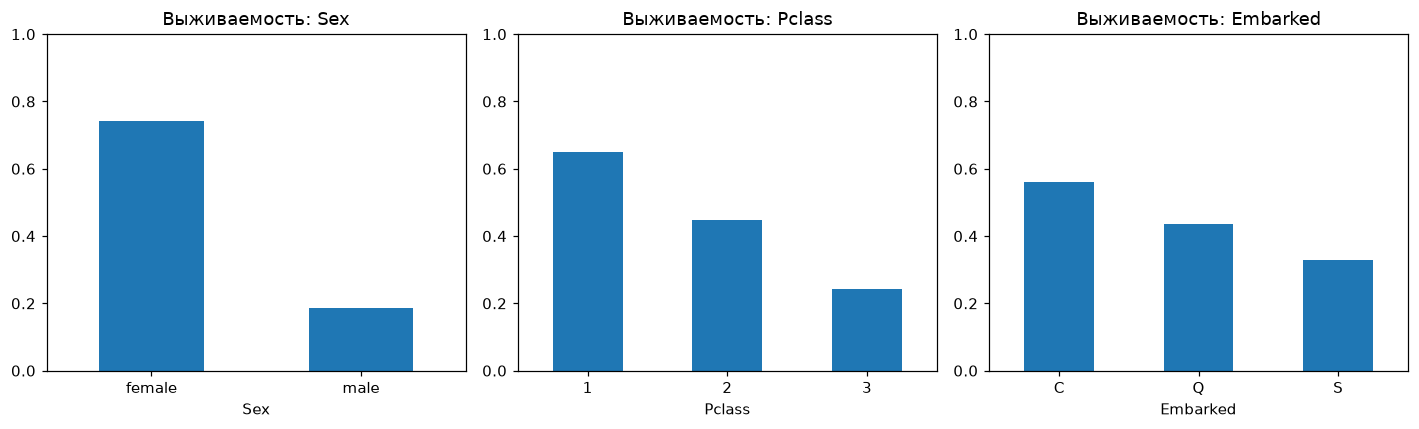

В данных 891 пассажир, выжили 342 (38.4%). Полных дубликатов 0. Пропуски: Age — 177, Cabin — 687, Embarked — 2. На train выживаемость женщин и пассажиров первого класса выше; это наблюдаемые связи, а не доказательство причинности. Fare имеет разные масштабы с возрастом и числом родственников; распределение цены асимметрично.

In [3]:
train_idx, test_idx = train_test_split(df.index, test_size=0.2, stratify=df.Survived, random_state=SEED)
train = df.loc[train_idx].copy()
artifacts['split.csv'] = pd.DataFrame({'PassengerId': df.PassengerId, 'split': np.where(df.index.isin(train_idx), 'train', 'test')}).to_csv(index=False)
print('train:', len(train_idx), 'test:', len(test_idx))
for col in ['Sex','Pclass','Embarked']:
    table(train.groupby(col, dropna=False).Survived.agg(['count','mean']).rename(columns={'mean':'survival_rate'}))
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ['Sex','Pclass','Embarked']):
    train.groupby(col).Survived.mean().plot.bar(ax=ax, ylim=(0,1), title=f'Выживаемость: {col}', rot=0)
figure('eda_survival.png')
note(f'В данных {len(df)} пассажир, выжили {df.Survived.sum()} '
     f'({df.Survived.mean():.1%}). Полных дубликатов {df.duplicated().sum()}. '
     f'Пропуски: Age — {df.Age.isna().sum()}, Cabin — {df.Cabin.isna().sum()}, '
     f'Embarked — {df.Embarked.isna().sum()}. '
     'На train выживаемость женщин и пассажиров первого класса выше; '
     'это наблюдаемые связи, а не доказательство причинности. Fare имеет разные '
     'масштабы с возрастом и числом родственников; распределение цены асимметрично.')

## 2. Подготовка без утечек
Используем Age, SibSp, Parch, Fare и категории Pclass, Sex, Embarked.
Pclass кодируем как категорию, чтобы расстояние между классами не задавать
произвольно. Age и другие числовые пропуски заменяем медианой (устойчивее
среднего к выбросам), категориальные — модой. One-hot не задаёт искусственный
порядок категорий, handle_unknown='ignore' допускает новые категории.

Для SVM и KNN числовые признаки стандартизируем: иначе Fare доминирует
в расстояниях, а RBF-ядро SVM и соседи KNN зависят от геометрии пространства.
Деревьям масштабирование не требуется, поскольку они сравнивают значения
с порогами. Imputer, scaler и encoder находятся внутри Pipeline и заново
обучаются на каждом обучающем CV-фолде. Test нигде не участвует в fit.

In [4]:
NUM = ['Age','SibSp','Parch','Fare']
CAT = ['Pclass','Sex','Embarked']
FEATURES = NUM + CAT
X_train, y_train = df.loc[train_idx, FEATURES], df.loc[train_idx, 'Survived']
X_test, y_test = df.loc[test_idx, FEATURES], df.loc[test_idx, 'Survived']
assert set(train_idx).isdisjoint(test_idx)
assert not set(['PassengerId','Name','Ticket','Cabin','Survived']) & set(FEATURES)
def preprocess(scaled=False):
    numeric = [('impute', SimpleImputer(strategy='median'))]
    if scaled:
        numeric.append(('scale', StandardScaler()))
    return ColumnTransformer([
        ('num', Pipeline(numeric), NUM),
        ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                          ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), CAT)
    ])
def pipeline(model, scaled=False):
    return Pipeline([('prepare', preprocess(scaled)), ('model', model)])
def metrics(y, prediction):
    return dict(Accuracy=accuracy_score(y, prediction),
                Precision=precision_score(y, prediction, zero_division=0),
                Recall=recall_score(y, prediction, zero_division=0),
                F1=f1_score(y, prediction, zero_division=0))

## 3. Dummy baseline
Сначала обучаем DummyClassifier(strategy='most_frequent'). Его финальные
тестовые метрики и confusion matrix будут рассчитаны вместе с остальными
моделями после завершения выбора параметров.

In [5]:
dummy = pipeline(DummyClassifier(strategy='most_frequent')).fit(X_train, y_train)
print('Dummy train:', metrics(y_train, dummy.predict(X_train)))

Dummy train: {'Accuracy': 0.6165730337078652, 'Precision': 0.0, 'Recall': 0.0, 'F1': 0.0}


## 4. Пять моделей и подбор на train
Используем одинаковые 5 стратифицированных фолдов, scoring='f1'.
Дерево ограничиваем глубиной и размером листа; лес — глубиной и листом;
бустинг — числом деревьев, глубиной и темпом обучения; SVM — C и gamma;
KNN — числом соседей и типом голосования. Сетки зафиксированы до оценки test.
Лучшая модель определяется по среднему CV F1; стандартное отклонение отражает
разброс по фолдам, а не доверительный интервал.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
specs = {
 'Decision Tree': (DecisionTreeClassifier(random_state=SEED), False,
                   {'model__max_depth':[3,5,7], 'model__min_samples_leaf':[2,5,10]}),
 'Random Forest': (RandomForestClassifier(n_estimators=250, random_state=SEED, n_jobs=1), False,
                   {'model__max_depth':[5,8,None], 'model__min_samples_leaf':[1,3,5]}),
 'Gradient Boosting': (GradientBoostingClassifier(random_state=SEED), False,
                   {'model__n_estimators':[100,200], 'model__learning_rate':[0.03,0.1],
                    'model__max_depth':[1,2,3]}),
 'SVM': (SVC(kernel='rbf'), True,
                   {'model__C':[0.5,1,3,10], 'model__gamma':['scale',0.03,0.1]}),
 'KNN': (KNeighborsClassifier(), True,
                   {'model__n_neighbors':[5,9,15,25], 'model__weights':['uniform','distance']})
}
models = {'Dummy':dummy}
cv_rows = []
for name, (model, scaled, grid) in specs.items():
    search = GridSearchCV(pipeline(model, scaled), grid, scoring='f1', cv=cv,
                          n_jobs=1, return_train_score=True, error_score='raise')
    search.fit(X_train, y_train)
    models[name] = search.best_estimator_
    k = search.best_index_
    cv_rows.append({'Model':name, 'CV_F1':search.best_score_,
                    'CV_std':search.cv_results_['std_test_score'][k],
                    'CV_train_F1':search.cv_results_['mean_train_score'][k],
                    'Parameters':str(search.best_params_)})
    artifacts[f"cv_{name.replace(' ', '_')}.csv"] = pd.DataFrame(search.cv_results_).to_csv(index=False)
    print(name, round(search.best_score_, 4), search.best_params_, flush=True)
cv_table = pd.DataFrame(cv_rows).set_index('Model').sort_values('CV_F1', ascending=False)
best_name = cv_table.index[0]
artifacts['cv_summary.csv'] = cv_table.to_csv()
table(cv_table)
note(f'До открытия тестовых результатов выбрана модель **{best_name}**, '
     f'CV F1 = {cv_table.iloc[0].CV_F1:.4f}. Это оценка после подбора параметров '
     'и может быть оптимистична; независимый test служит итоговой проверкой.')

Decision Tree 0.7331 {'model__max_depth': 7, 'model__min_samples_leaf': 5}
Random Forest 0.7467 {'model__max_depth': 5, 'model__min_samples_leaf': 1}
Gradient Boosting 0.7534 {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 100}
SVM 0.7625 {'model__C': 10, 'model__gamma': 0.03}
KNN 0.7472 {'model__n_neighbors': 25, 'model__weights': 'uniform'}


,CV_F1,CV_std,CV_train_F1,Parameters
Model,,,,
SVM,0.762503,0.038858,0.771889,"{'model__C': 10, 'model__gamma': 0.03}"
Gradient Boosting,0.753425,0.030978,0.880669,"{'model__learning_rate': 0.1, 'model__max_dept..."
KNN,0.747248,0.030267,0.763826,"{'model__n_neighbors': 25, 'model__weights': '..."
Random Forest,0.746737,0.038311,0.796164,"{'model__max_depth': 5, 'model__min_samples_le..."
Decision Tree,0.733078,0.025759,0.824163,"{'model__max_depth': 7, 'model__min_samples_le..."


До открытия тестовых результатов выбрана модель **SVM**, CV F1 = 0.7625. Это оценка после подбора параметров и может быть оптимистична; независимый test служит итоговой проверкой.

## 5. Единственная финальная оценка на test
Все модели используют одни объекты, одинаковые метрики и стандартный predict.
Порог F1 > 0.70 проверяется строго. Порядок тестового leaderboard не меняет
выбор модели, сделанный по CV.
FP — погибший пассажир ошибочно назван выжившим.
FN — выживший ошибочно назван погибшим. В этой исторической задаче речь идёт
об ошибках прогнозирования, а не о решениях по спасению людей.

,Accuracy,Precision,Recall,F1,F1 > 0.70
SVM,0.826816,0.827586,0.695652,0.755906,True
Decision Tree,0.793296,0.775862,0.652174,0.708661,True
KNN,0.793296,0.775862,0.652174,0.708661,True
Random Forest,0.810056,0.872340,0.594203,0.706897,True
Gradient Boosting,0.793296,0.785714,0.637681,0.704000,True
Dummy,0.614525,0.000000,0.000000,0.000000,False


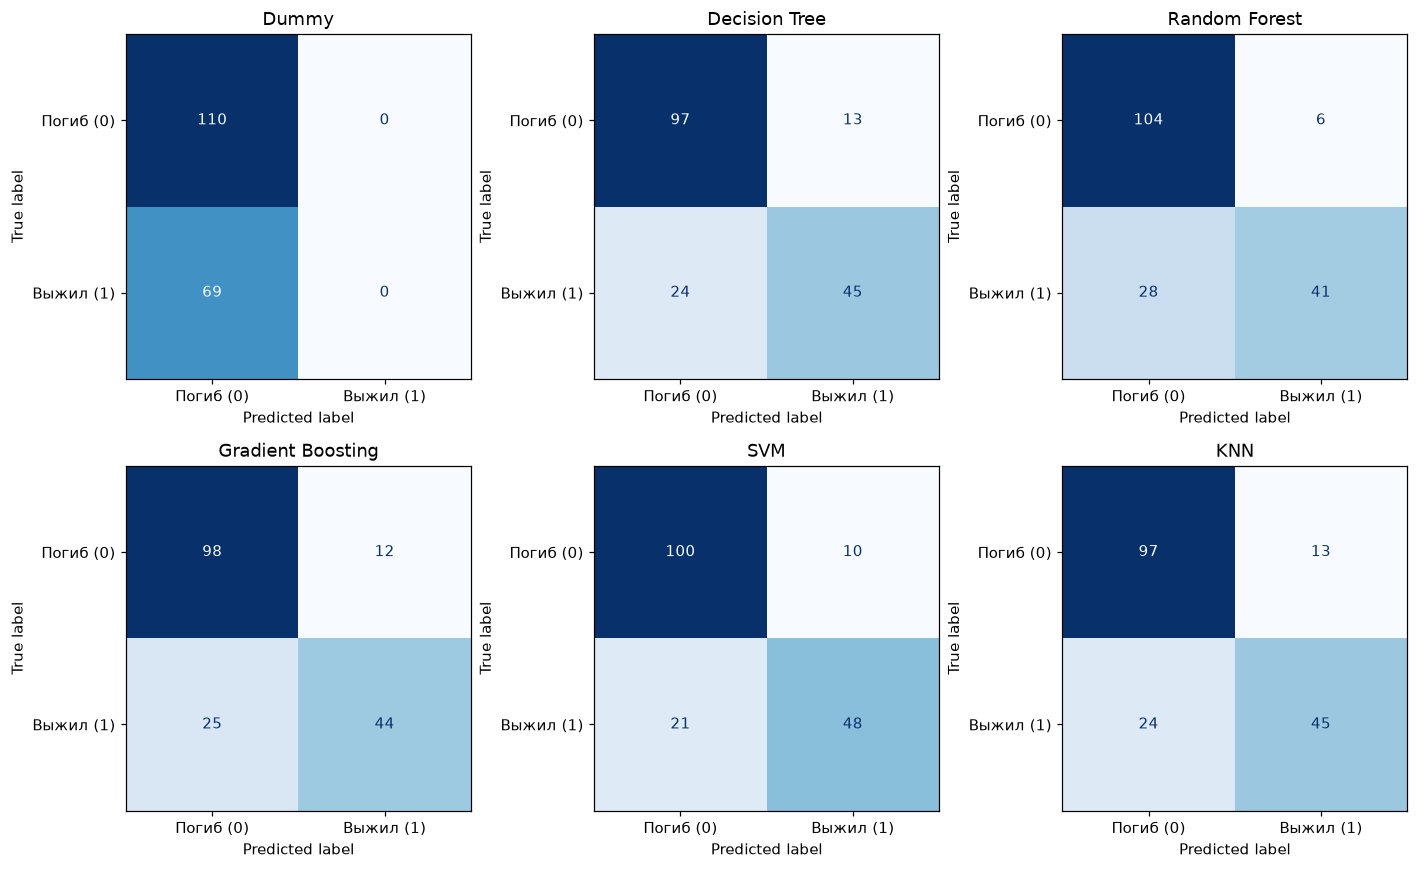

,TN,FP,FN,TP
Model,,,,
Dummy,110,0,69,0
Decision Tree,97,13,24,45
Random Forest,104,6,28,41
Gradient Boosting,98,12,25,44
SVM,100,10,21,48
KNN,97,13,24,45


**Dummy**: FP=0, FN=69, precision=0.000, recall=0.000. Чаще пропускает выживших.

**Decision Tree**: FP=13, FN=24, precision=0.776, recall=0.652. Чаще пропускает выживших.

**Random Forest**: FP=6, FN=28, precision=0.872, recall=0.594. Чаще пропускает выживших.

**Gradient Boosting**: FP=12, FN=25, precision=0.786, recall=0.638. Чаще пропускает выживших.

**SVM**: FP=10, FN=21, precision=0.828, recall=0.696. Чаще пропускает выживших.

**KNN**: FP=13, FN=24, precision=0.776, recall=0.652. Чаще пропускает выживших.

Строгий порог F1 > 0.70 преодолели: SVM, Decision Tree, KNN, Random Forest, Gradient Boosting. Dummy демонстрирует ограниченность accuracy при дисбалансе: предсказание большинства не находит выживших. Различия моделей связаны с ограничениями дерева, усреднением леса, последовательным исправлением ошибок бустингом и геометрией границы SVM/KNN. Один split не доказывает статистически значимого превосходства близких результатов.

Gradient Boosting: F1=0.7040, Random Forest: F1=0.7069, разность GB − RF = -0.0029. Бустинг исправляет ошибки последовательно, лес уменьшает разброс за счёт ансамбля; наблюдаемая разность относится к заданным сеткам и этому test.

In [7]:
predictions = {name: model.predict(X_test) for name, model in models.items()}
leaderboard = pd.DataFrame({name:metrics(y_test, pred) for name,pred in predictions.items()}).T
leaderboard['F1 > 0.70'] = leaderboard.F1 > 0.70
leaderboard = leaderboard.sort_values('F1', ascending=False)
artifacts['leaderboard.csv'] = leaderboard.to_csv()
table(leaderboard)
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
error_rows = []
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[0,1])
    ConfusionMatrixDisplay(cm, display_labels=['Погиб (0)','Выжил (1)']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
    tn, fp, fn, tp = cm.ravel()
    error_rows.append({'Model':name,'TN':tn,'FP':fp,'FN':fn,'TP':tp})
figure('confusion_matrices.png')
table(pd.DataFrame(error_rows).set_index('Model'))
for row in error_rows:
    name = row['Model']
    note(f"**{name}**: FP={row['FP']}, FN={row['FN']}, "
         f"precision={leaderboard.loc[name, 'Precision']:.3f}, "
         f"recall={leaderboard.loc[name, 'Recall']:.3f}. "
         + ('Чаще пропускает выживших.' if row['FN'] > row['FP'] else
            'Чаще ошибочно предсказывает выживание.' if row['FP'] > row['FN'] else 'Число FP и FN одинаково.'))
passed = leaderboard.index[leaderboard['F1 > 0.70']].tolist()
note('Строгий порог F1 > 0.70 преодолели: ' + ', '.join(passed) + '. '
     'Dummy демонстрирует ограниченность accuracy при дисбалансе: '
     'предсказание большинства не находит выживших. Различия моделей связаны '
     'с ограничениями дерева, усреднением леса, последовательным исправлением '
     'ошибок бустингом и геометрией границы SVM/KNN. Один split не доказывает '
     'статистически значимого превосходства близких результатов.')
rf_f1 = leaderboard.loc['Random Forest','F1']; gb_f1 = leaderboard.loc['Gradient Boosting','F1']
note(f'Gradient Boosting: F1={gb_f1:.4f}, Random Forest: F1={rf_f1:.4f}, '
     f'разность GB − RF = {gb_f1-rf_f1:+.4f}. '
     'Бустинг исправляет ошибки последовательно, лес уменьшает разброс за счёт ансамбля; '
     'наблюдаемая разность относится к заданным сеткам и этому test.')

In [8]:
train_test = pd.DataFrame({name:{'train_F1':f1_score(y_train, model.predict(X_train)),
                               'test_F1':leaderboard.loc[name,'F1'],
                               'train_accuracy':accuracy_score(y_train, model.predict(X_train)),
                               'test_accuracy':leaderboard.loc[name,'Accuracy']}
                           for name,model in models.items()}).T
train_test['F1_gap'] = train_test.train_F1 - train_test.test_F1
artifacts['train_test.csv'] = train_test.to_csv(); table(train_test)
unrestricted = pipeline(DecisionTreeClassifier(random_state=SEED)).fit(X_train, y_train)
note(f'У выбранного дерева train F1={train_test.loc["Decision Tree","train_F1"]:.4f}, '
     f'test F1={train_test.loc["Decision Tree","test_F1"]:.4f}. '
     f'В CV train F1={cv_table.loc["Decision Tree","CV_train_F1"]:.4f}, '
     f'validation F1={cv_table.loc["Decision Tree","CV_F1"]:.4f}. '
     'Разрыв train/validation указывает на признаки переобучения; ограничения '
     'сложности его сдерживают. Один train/test разрыв также зависит от состава test. '
     f'Для иллюстрации запоминания неограниченное дерево имеет train F1='
     f'{f1_score(y_train, unrestricted.predict(X_train)):.4f}; оно не участвует в выборе по test.')

,train_F1,test_F1,train_accuracy,test_accuracy,F1_gap
Dummy,0.000000,0.000000,0.616573,0.614525,0.000000
Decision Tree,0.825832,0.708661,0.875000,0.793296,0.117170
Random Forest,0.785276,0.706897,0.852528,0.810056,0.078380
Gradient Boosting,0.865497,0.704000,0.903090,0.793296,0.161497
SVM,0.769531,0.755906,0.834270,0.826816,0.013626
KNN,0.768924,0.708661,0.837079,0.793296,0.060263


У выбранного дерева train F1=0.8258, test F1=0.7087. В CV train F1=0.8242, validation F1=0.7331. Разрыв train/validation указывает на признаки переобучения; ограничения сложности его сдерживают. Один train/test разрыв также зависит от состава test. Для иллюстрации запоминания неограниченное дерево имеет train F1=0.9776; оно не участвует в выборе по test.

## 6. Важность признаков
Сравним impurity-based importance трёх моделей. Для исходного категориального
признака складываем важности всех его one-hot столбцов. Это позволяет
сопоставить модели на одном наборе семи признаков. Такая важность смещена
к признакам с большим числом порогов; коррелирующие признаки делят вклад.
Она описывает использование признака обученной моделью, но не причинность.

,Decision Tree,Random Forest,Gradient Boosting
Age,0.130637,0.102574,0.150248
SibSp,0.006651,0.033537,0.028099
Parch,0.001052,0.031339,0.001603
Fare,0.171848,0.131986,0.178282
Pclass,0.169887,0.155101,0.153431
Sex,0.488400,0.511916,0.465995
Embarked,0.031524,0.033547,0.022341


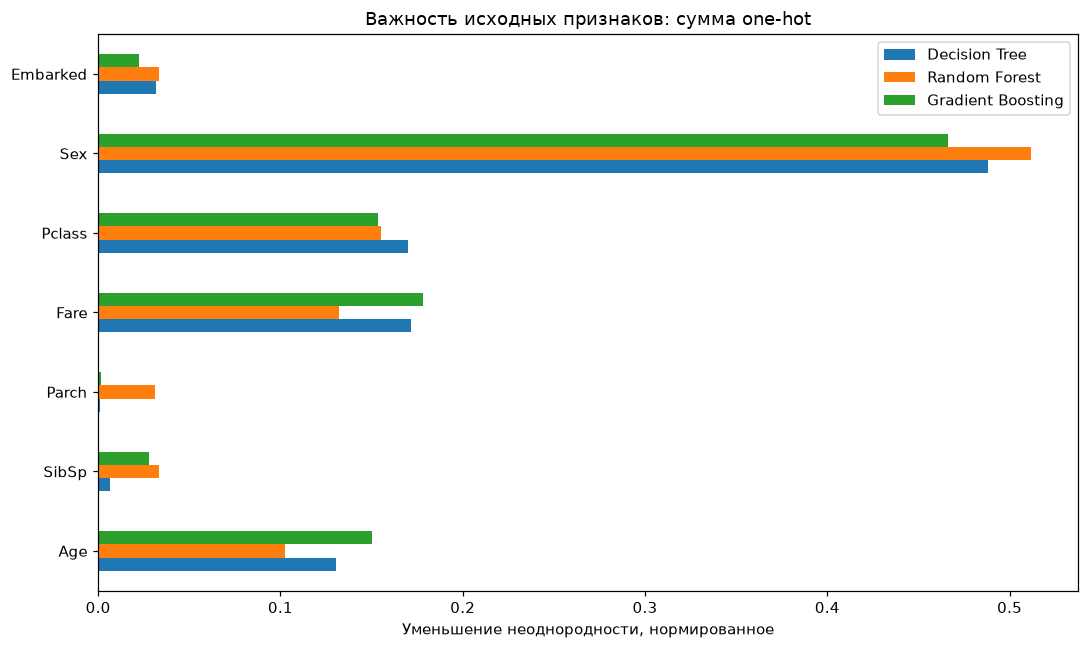

**Decision Tree**, три наиболее важных: Sex, Fare, Pclass.

**Random Forest**, три наиболее важных: Sex, Pclass, Fare.

**Gradient Boosting**, три наиболее важных: Sex, Fare, Pclass.

Важность Sex/Pclass согласуется с различиями выживаемости на train. Fare связан с Pclass, поэтому модели могут распределять важность между ними по-разному. Age помогает выделять возрастные группы, SibSp/Parch описывают семейный контекст. Ни важность, ни EDA не доказывают, что изменение одного признака изменило бы судьбу пассажира: данные наблюдательные, есть смешивающие факторы и отсутствуют сведения о положении на судне и доступе к шлюпкам.

In [9]:
importance = {}
for name in ['Decision Tree','Random Forest','Gradient Boosting']:
    prep = models[name].named_steps['prepare']
    encoded_names = prep.get_feature_names_out()
    values = models[name].named_steps['model'].feature_importances_
    mapping = {}
    for f,v in zip(encoded_names,values):
        raw = f.split('__',1)[1]
        origin = next((c for c in CAT if raw.startswith(c+'_')),raw)
        mapping[origin] = mapping.get(origin,0) + v
    importance[name] = pd.Series(mapping)
    artifacts[f"importance_encoded_{name.replace(' ', '_')}.csv"] = pd.Series(values, index=encoded_names, name='importance').to_csv()
importance = pd.DataFrame(importance).fillna(0)
assert np.allclose(importance.sum(),1)
artifacts['feature_importance.csv'] = importance.to_csv(); table(importance)
importance.plot.barh(figsize=(10,6), title='Важность исходных признаков: сумма one-hot')
plt.xlabel('Уменьшение неоднородности, нормированное'); figure('feature_importance.png')
for name in importance:
    note(f'**{name}**, три наиболее важных: ' + ', '.join(importance[name].nlargest(3).index) + '.')
note('Важность Sex/Pclass согласуется с различиями выживаемости на train. '
     'Fare связан с Pclass, поэтому модели могут распределять важность между ними '
     'по-разному. Age помогает выделять возрастные группы, SibSp/Parch описывают '
     'семейный контекст. Ни важность, ни EDA не доказывают, что изменение одного '
     'признака изменило бы судьбу пассажира: данные наблюдательные, есть смешивающие '
     'факторы и отсутствуют сведения о положении на судне и доступе к шлюпкам.')

## 7. Разбор ошибок выбранной по CV модели
Группы и отдельные ошибки рассматриваются после финальной оценки только
для объяснения. На основании этого анализа модель и параметры не меняются.

In [10]:
best_pred = predictions[best_name]
audit = df.loc[test_idx].copy()
audit['prediction'] = best_pred
audit['error'] = (audit.Survived != audit.prediction).astype(int)
audit['FP'] = ((audit.Survived==0)&(audit.prediction==1)).astype(int)
audit['FN'] = ((audit.Survived==1)&(audit.prediction==0)).astype(int)
audit['AgeGroup'] = pd.cut(audit.Age, bins=[0,12,18,40,60,np.inf],
                           labels=['0–12','13–18','19–40','41–60','61+'], include_lowest=True).astype('object').fillna('Unknown')
artifacts['test_predictions.csv'] = audit.to_csv(index=False)
for group in ['Sex','Pclass','AgeGroup']:
    groups = audit.groupby(group,dropna=False).agg(n=('error','size'), errors=('error','sum'),
                            error_rate=('error','mean'), FP=('FP','sum'), FN=('FN','sum'))
    table(groups)
    artifacts[f'errors_by_{group}.csv'] = groups.to_csv()
    substantial = groups[groups.n >= 10].sort_values('error_rate',ascending=False)
    if len(substantial):
        g = substantial.index[0]; r = substantial.iloc[0]
        note(f'По {group} самая высокая доля ошибок среди групп с n≥10: '
             f'**{g}**, {int(r.errors)}/{int(r.n)} = {r.error_rate:.1%}. '
             'Размер группы следует учитывать; это описательная оценка, не проверка значимости.')
tn,fp,fn,tp = confusion_matrix(y_test,best_pred,labels=[0,1]).ravel()
note(f'Выбранная по CV **{best_name}**: TN={tn}, FP={fp}, FN={fn}, TP={tp}; '
     + ('чаще встречаются FN — пропуски выживших.' if fn>fp else
        'чаще встречаются FP — ложные прогнозы выживания.' if fp>fn else 'FP и FN поровну.'))
errors = audit[audit.error==1]
examples = pd.concat([errors[errors.FP==1].head(3), errors[errors.FN==1].head(3)])
table(examples[['PassengerId','Sex','Pclass','Age','Fare','SibSp','Parch','Survived','prediction']].set_index('PassengerId'))
for _,r in examples.iterrows():
    possible = ('Мужчина мог попасть в группу с низкой обучающей выживаемостью. '
                if r.Sex=='male' and r.FN else
                'Женщина могла попасть в группу с высокой обучающей выживаемостью. '
                if r.Sex=='female' and r.FP else
                'Комбинация признаков могла быть похожа на пассажиров другого класса исхода. ')
    if pd.isna(r.Age):
        possible += 'Возраст отсутствует и заменён общей медианой, индивидуальная информация потеряна. '
    note(f'PassengerId={int(r.PassengerId)}: истина={int(r.Survived)}, прогноз={int(r.prediction)}. '
         + possible + 'Это гипотезы; данных о фактическом доступе к спасению нет.')

,n,errors,error_rate,FP,FN
Sex,,,,,
female,61,10,0.163934,9,1
male,118,21,0.177966,1,20


По Sex самая высокая доля ошибок среди групп с n≥10: **male**, 21/118 = 17.8%. Размер группы следует учитывать; это описательная оценка, не проверка значимости.

,n,errors,error_rate,FP,FN
Pclass,,,,,
1,45,10,0.222222,1,9
2,34,4,0.117647,2,2
3,100,17,0.170000,7,10


По Pclass самая высокая доля ошибок среди групп с n≥10: **1**, 10/45 = 22.2%. Размер группы следует учитывать; это описательная оценка, не проверка значимости.

,n,errors,error_rate,FP,FN
AgeGroup,,,,,
0–12,14,3,0.214286,1,2
13–18,17,0,0.000000,0,0
19–40,79,17,0.215190,5,12
41–60,23,2,0.086957,0,2
61+,6,1,0.166667,0,1
Unknown,40,8,0.200000,4,4


...

PassengerId=41: истина=0, прогноз=1. Женщина могла попасть в группу с высокой обучающей выживаемостью. Это гипотезы; данных о фактическом доступе к спасению нет.

PassengerId=565: истина=0, прогноз=1. Женщина могла попасть в группу с высокой обучающей выживаемостью. Возраст отсутствует и заменён общей медианой, индивидуальная информация потеряна. Это гипотезы; данных о фактическом доступе к спасению нет.

PassengerId=554: истина=1, прогноз=0. Мужчина мог попасть в группу с низкой обучающей выживаемостью. Это гипотезы; данных о фактическом доступе к спасению нет.

PassengerId=280: истина=1, прогноз=0. Комбинация признаков могла быть похожа на пассажиров другого класса исхода. Это гипотезы; данных о фактическом доступе к спасению нет.

PassengerId=713: истина=1, прогноз=0. Мужчина мог попасть в группу с низкой обучающей выживаемостью. Это гипотезы; данных о фактическом доступе к спасению нет.

## 8. Проверка идентификации и ограничения
PassengerId используется только для сохранения split и пояснения ошибок,
Name/Ticket/Cabin исключены. Survived отделён от X до построения Pipeline.
Ни один параметр препроцессинга не оценивается на test, CV включает Pipeline.
Все исходные признаки доступны до исхода, производные от Survived не создаются.
Высокое качество не связано с прямым использованием идентификаторов.
Тем не менее родственники и пассажиры одного билета могут находиться в разных
частях: это ограничение случайного разбиения, не гарантия независимости групп.
Для сценария «новые семьи» нужен отдельный group split и новая оценка.
Общее тестовое множество группы нужно получить у преподавателя; текущие цифры
не заявляются официальным результатом leaderboard.

In [11]:
shared_tickets = set(df.loc[train_idx,'Ticket']) & set(df.loc[test_idx,'Ticket'])
print('Общих билетов между train/test:',len(shared_tickets))
print('Тестовых пассажиров с билетом, встреченным в train:',df.loc[test_idx,'Ticket'].isin(shared_tickets).sum())
note(f'Проверка зависимостей: {len(shared_tickets)} билетов встречаются в обеих частях; '
     'Ticket не используется как признак, но родственные наблюдения могут иметь похожие '
     'характеристики. Это ограничивает перенос результата на независимые группы.')
note(f'Итог: выбранная по CV модель **{best_name}**, тестовый '
     f'F1={leaderboard.loc[best_name,"F1"]:.4f}, '
     f'Accuracy={leaderboard.loc[best_name,"Accuracy"]:.4f}. '
     f'Максимальный F1 в описательной тестовой таблице — '
     f'{leaderboard.F1.max():.4f} ({leaderboard.F1.idxmax()}); '
     'выбор и настройки после просмотра test не пересматриваются. '
     'Результаты, метрики, параметры, split и иллюстрации сохранены в этом ноутбуке.')


assert len(leaderboard)==6
assert leaderboard.loc['Dummy','F1']==0
assert leaderboard.loc[best_name,'F1']>0.70, 'Выбранная модель не преодолела порог'


Общих билетов между train/test: 61
Тестовых пассажиров с билетом, встреченным в train: 67


Проверка зависимостей: 61 билетов встречаются в обеих частях; Ticket не используется как признак, но родственные наблюдения могут иметь похожие характеристики. Это ограничивает перенос результата на независимые группы.

Итог: выбранная по CV модель **SVM**, тестовый F1=0.7559, Accuracy=0.8268. Максимальный F1 в описательной тестовой таблице — 0.7559 (SVM); выбор и настройки после просмотра test не пересматриваются. Результаты, метрики, параметры, split и иллюстрации сохранены в этом ноутбуке.